# Ex5: PCA on land-cover and autoencoder super-resolution

Kernel: **ml4space**. Images from `ex1/satellite_images` (forest, urban, ocean).

Task:
1. Take patches from different land-cover types, run PCA to 3 dims, check if they cluster.
2. Use an autoencoder for super-resolution on an EO image (idea from the lecture Colab link).


## Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras import layers, Model, regularizers

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

IMG_DIR = Path("../ex1/satellite_images")
PATCH = 64
rng = np.random.default_rng(42)

print("TF", tf.__version__)


TF 2.21.0


# Part 1: PCA on land-cover patches

We cut small patches from forest, urban and ocean. Each patch is one sample (flattened RGB).
PCA keeps 3 components so we can plot in 3D and see if the classes sit in different places.


data shape: (240, 12288)


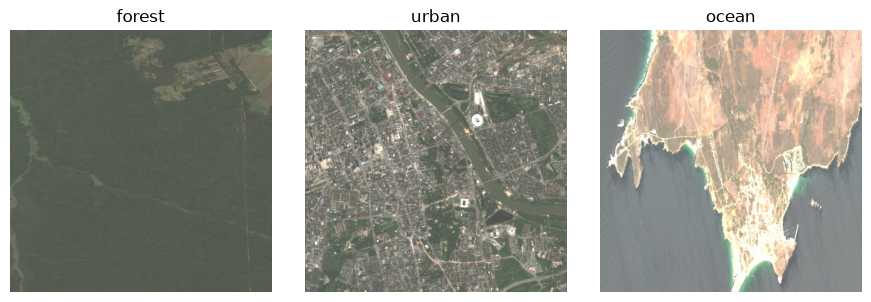

In [2]:
def load_rgb(name):
    return np.asarray(Image.open(IMG_DIR / name).convert("RGB"), dtype=np.float32) / 255.0

def sample_patches(img, n, label):
    h, w, _ = img.shape
    X, y = [], []
    for _ in range(n):
        yy = int(rng.integers(0, h - PATCH + 1))
        xx = int(rng.integers(0, w - PATCH + 1))
        p = img[yy:yy + PATCH, xx:xx + PATCH]
        X.append(p.reshape(-1))
        y.append(label)
    return np.asarray(X, dtype=np.float32), np.asarray(y)

forest = load_rgb("forest_poland.jpg")
urban = load_rgb("urban_poland.jpg")
ocean = load_rgb("ocean_portugal.jpg")

X_f, y_f = sample_patches(forest, 80, 0)
X_u, y_u = sample_patches(urban, 80, 1)
X_o, y_o = sample_patches(ocean, 80, 2)

X = np.vstack([X_f, X_u, X_o])
y = np.concatenate([y_f, y_u, y_o])
print("data shape:", X.shape)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, img, title in zip(axes, [forest, urban, ocean], ["forest", "urban", "ocean"]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()


explained variance ratio: [0.74427646 0.03527671 0.01820474]
sum of first 3: 0.7977579


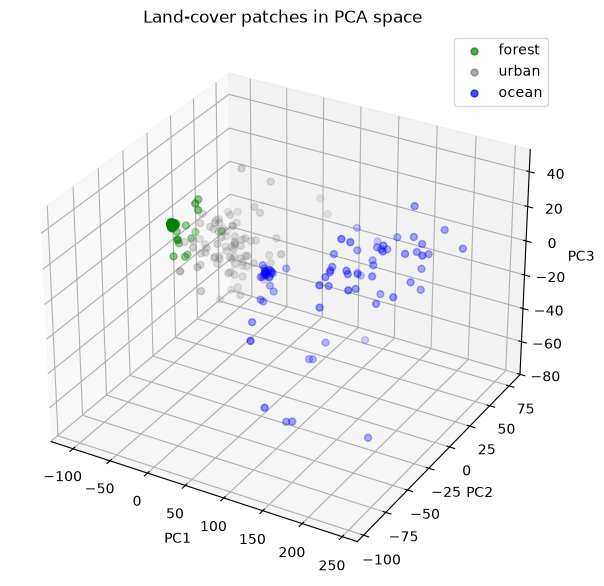

In [3]:
scaler = StandardScaler()
X_s = scaler.fit_transform(X)

pca = PCA(n_components=3)
X_pc = pca.fit_transform(X_s)

print("explained variance ratio:", pca.explained_variance_ratio_)
print("sum of first 3:", pca.explained_variance_ratio_.sum())

colors = {0: "green", 1: "gray", 2: "blue"}
names = {0: "forest", 1: "urban", 2: "ocean"}

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for lab in [0, 1, 2]:
    m = y == lab
    ax.scatter(X_pc[m, 0], X_pc[m, 1], X_pc[m, 2], c=colors[lab], label=names[lab], s=25, alpha=0.7)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.legend()
ax.set_title("Land-cover patches in PCA space")
plt.tight_layout()
plt.show()


### Short comment on PCA

The three land-cover types form clear groups in PC space. Forest, urban and ocean have different color stats, so PCA can separate them even with only 3 components. Overlap can happen if a patch mixes two classes or if lighting is similar.


# Part 2: Autoencoder super-resolution

Lecture points to a Colab autoencoder for super-resolution. Same idea here, but on our EO patches.

We make a low-res version by shrinking the patch and stretching it back. The net learns to map that blurry input back to the sharp patch.


train pairs: (240, 64, 64, 3) scale: 4


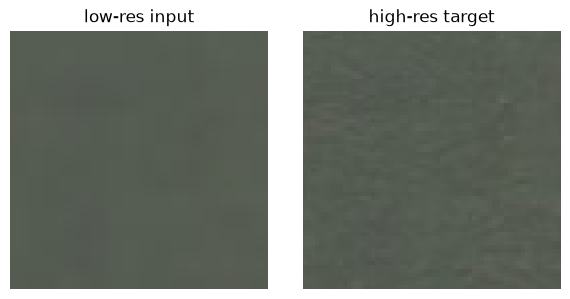

In [4]:
N = 64  # patch size for the autoencoder
SCALE = 4  # stronger blur so the task is clearer

def make_pairs(imgs, n_per_img=60):
    X_lr, X_hr = [], []
    for img in imgs:
        h, w, _ = img.shape
        for _ in range(n_per_img):
            yy = int(rng.integers(0, h - N + 1))
            xx = int(rng.integers(0, w - N + 1))
            hr = img[yy:yy + N, xx:xx + N]
            small = np.asarray(
                Image.fromarray((hr * 255).astype(np.uint8)).resize(
                    (N // SCALE, N // SCALE), Image.BILINEAR
                )
            )
            lr = np.asarray(
                Image.fromarray(small).resize((N, N), Image.BILINEAR), dtype=np.float32
            ) / 255.0
            X_lr.append(lr)
            X_hr.append(hr)
    return np.asarray(X_lr, dtype=np.float32), np.asarray(X_hr, dtype=np.float32)

x_lr, x_hr = make_pairs([forest, urban, ocean], n_per_img=80)
print("train pairs:", x_lr.shape, "scale:", SCALE)

i = 3
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(x_lr[i]); ax[0].set_title("low-res input"); ax[0].axis("off")
ax[1].imshow(x_hr[i]); ax[1].set_title("high-res target"); ax[1].axis("off")
plt.tight_layout()
plt.show()


In [5]:
def build_sr_autoencoder(n=N, chan=3):
    # same style as the lecture Colab: conv encoder + upsample decoder + skip links
    reg = regularizers.l1(1e-9)
    inp = layers.Input(shape=(n, n, chan))

    l1 = layers.Conv2D(32, 3, padding="same", activation="relu", activity_regularizer=reg)(inp)
    l2 = layers.Conv2D(32, 3, padding="same", activation="relu", activity_regularizer=reg)(l1)
    l3 = layers.MaxPooling2D(padding="same")(l2)

    l4 = layers.Conv2D(64, 3, padding="same", activation="relu", activity_regularizer=reg)(l3)
    l5 = layers.Conv2D(64, 3, padding="same", activation="relu", activity_regularizer=reg)(l4)
    l6 = layers.MaxPooling2D(padding="same")(l5)

    l7 = layers.Conv2D(128, 3, padding="same", activation="relu", activity_regularizer=reg)(l6)

    l8 = layers.UpSampling2D()(l7)
    l9 = layers.Conv2D(64, 3, padding="same", activation="relu", activity_regularizer=reg)(l8)
    l10 = layers.Conv2D(64, 3, padding="same", activation="relu", activity_regularizer=reg)(l9)
    l11 = layers.Add()([l5, l10])

    l12 = layers.UpSampling2D()(l11)
    l13 = layers.Conv2D(32, 3, padding="same", activation="relu", activity_regularizer=reg)(l12)
    l14 = layers.Conv2D(32, 3, padding="same", activation="relu", activity_regularizer=reg)(l13)
    l15 = layers.Add()([l14, l2])

    out = layers.Conv2D(chan, 3, padding="same", activation="sigmoid", activity_regularizer=reg)(l15)
    model = Model(inp, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    return model

ae = build_sr_autoencoder()
ae.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_4[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │     73,792 │ up_sampling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_5[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d_3[0][0],   │
│                     │ 64)               │            │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ add[0][0]         │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │     18,464 │ up_sampling2d_1[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_7[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64,    │          0 │ conv2d_8[0][0],   │
│                     │ 32)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 64, 64, 3) │        867 │ add_1[0][0]     

 Total params: 278,723 (1.06 MB)

 Trainable params: 278,723 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 90ms/step - loss: 0.0253 - val_loss: 0.0514
Epoch 2/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 0.0140 - val_loss: 0.0143
Epoch 3/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 0.0088 - val_loss: 0.0141
Epoch 4/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - loss: 0.0056 - val_loss: 0.0148
Epoch 5/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 0.0058 - val_loss: 0.0094
Epoch 6/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - loss: 0.0049 - val_loss: 0.0083
Epoch 7/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - loss: 0.0039 - val_loss: 0.0080
Epoch 8/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - loss: 0.0040 - val_loss: 0.0095
Epoch 9/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 0.0043 - val_loss: 0.0071
Epoch 10/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - loss: 0.0042 - val_loss: 0.0062
Epoch 11/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - loss: 0.0032 - val_loss: 0.0058
Epoch 12/40
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - loss: 0.0

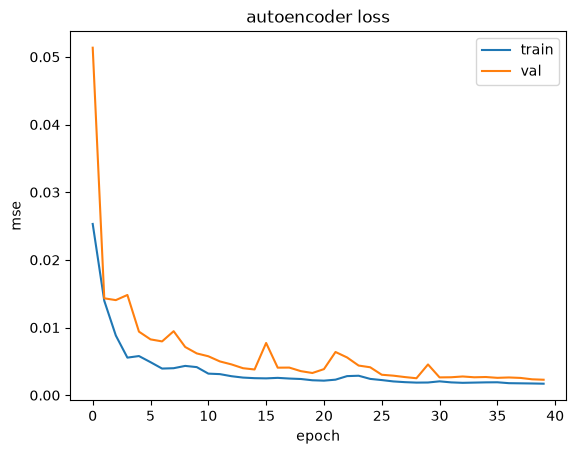

In [6]:
hist = ae.fit(x_lr, x_hr, epochs=40, batch_size=16, validation_split=0.15, verbose=1)

plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel("mse")
plt.legend()
plt.title("autoencoder loss")
plt.show()


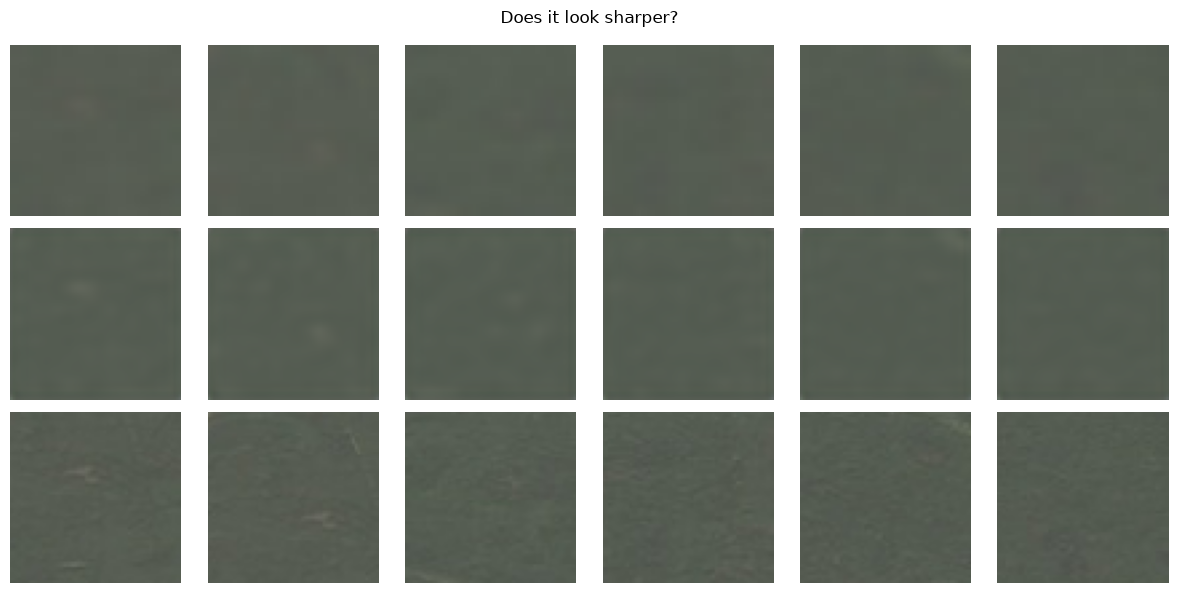

mse low-res vs HR: 0.00005
mse AE vs HR:      0.00007


In [7]:
pred = ae.predict(x_lr[:6], verbose=0)

fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for j in range(6):
    axes[0, j].imshow(np.clip(x_lr[j], 0, 1))
    axes[0, j].axis("off")
    if j == 0:
        axes[0, j].set_ylabel("low-res")
    axes[1, j].imshow(np.clip(pred[j], 0, 1))
    axes[1, j].axis("off")
    if j == 0:
        axes[1, j].set_ylabel("AE out")
    axes[2, j].imshow(np.clip(x_hr[j], 0, 1))
    axes[2, j].axis("off")
    if j == 0:
        axes[2, j].set_ylabel("true HR")
plt.suptitle("Does it look sharper?")
plt.tight_layout()
plt.show()

mse_in = np.mean((x_lr[:6] - x_hr[:6]) ** 2)
mse_out = np.mean((pred - x_hr[:6]) ** 2)
print(f"mse low-res vs HR: {mse_in:.5f}")
print(f"mse AE vs HR:      {mse_out:.5f}")


### Does it enhance the resolution?

A little. The AE tries to put back detail lost in the blur. On these few EO crops the gain is small. MSE can stay close to simple resize, so do not expect a big wow.

### How to make it work better?

- more patches and more epochs
- train on many EO scenes, not only 3 crops
- use a pretrained model like in the lecture Colab
- try SSIM loss instead of only MSE
- bigger net if you have more data
